### Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

# Change this to your actual dataset filename

df = pd.read_csv(r"C:\Users\Admin\Desktop\Training\Python Training\25-11-2026\data\clean_data.csv")


# Set chart style
sns.set_theme(style="whitegrid")

# Display dataset
print(df.head())

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   36       Yes      Travel_Rarely       1102                   Sales   
1   36        No  Travel_Frequently        279  Research & Development   
2   36       Yes      Travel_Rarely       1373  Research & Development   
3   36        No  Travel_Frequently       1392  Research & Development   
4   36        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

### Bar Chart - Attrition by Department

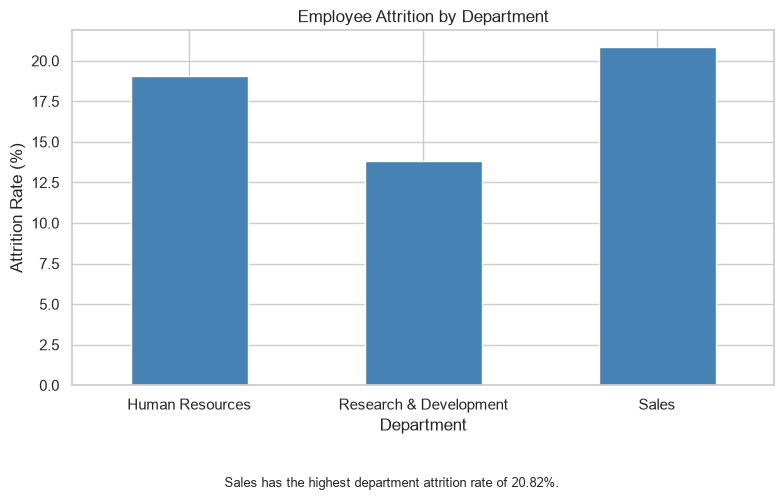

Insight: Sales has the highest department attrition rate of 20.82%.


In [2]:
# Calculate attrition rate
department_attrition = (
    df.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

plt.figure(figsize=(8, 5))

department_attrition.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)

insight = (
    f"{department_attrition.idxmax()} has the highest "
    f"department attrition rate of "
    f"{department_attrition.max():.2f}%."
)

plt.figtext(0.5, 0.01, insight, ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    r"C:\Users\Admin\Desktop\Training\Python Training\25-11-2026\Task_3\reports\figures\01_department_attrition.png"
)

plt.show()

print("Insight:", insight)

### Histogram - Monthly Income Distribution

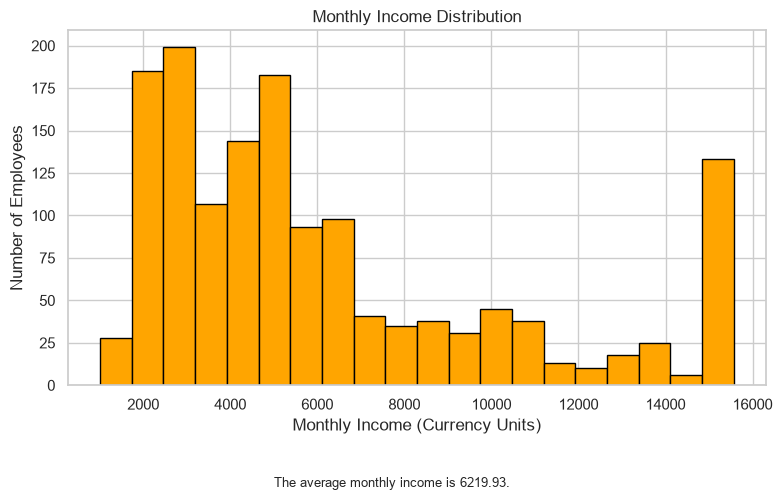

Insight: The average monthly income is 6219.93.


In [3]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["MonthlyIncome"],
    bins=20,
    color="orange",
    edgecolor="black"
)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income (Currency Units)")
plt.ylabel("Number of Employees")

insight = (
    f"The average monthly income is "
    f"{df['MonthlyIncome'].mean():.2f}."
)

plt.figtext(0.5, 0.01, insight, ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    r"C:\Users\Admin\Desktop\Training\Python Training\25-11-2026\Task_3\reports\figures\02_monthly_income_histogram.png"
)

plt.show()

print("Insight:", insight)

### Scatter Plot:  Age vs Monthly Income

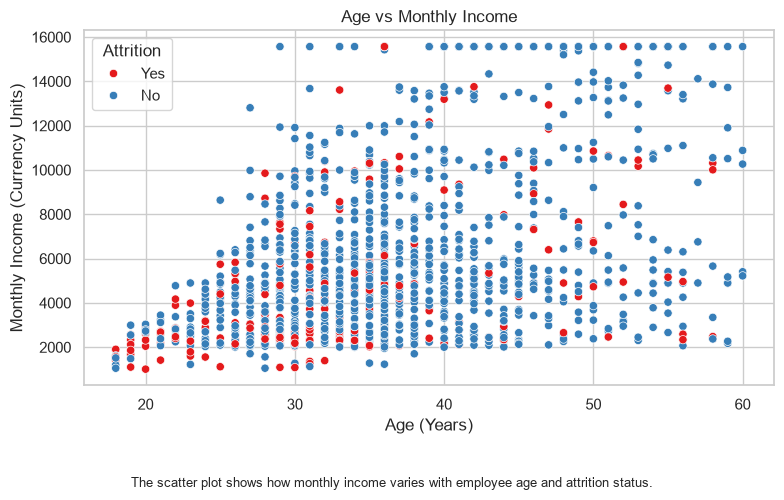

Insight: The scatter plot shows how monthly income varies with employee age and attrition status.


In [4]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="MonthlyIncome",
    hue="Attrition",
    palette="Set1"
)

plt.title("Age vs Monthly Income")
plt.xlabel("Age (Years)")
plt.ylabel("Monthly Income (Currency Units)")
plt.legend(title="Attrition")

insight = (
    "The scatter plot shows how monthly income varies "
    "with employee age and attrition status."
)

plt.figtext(0.5, 0.01, insight, ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    r"C:\Users\Admin\Desktop\Training\Python Training\25-11-2026\Task_3\reports\figures\03_age_income_scatter.png"
)

plt.show()

print("Insight:", insight)

### Line Chart - Attrition by Age Group

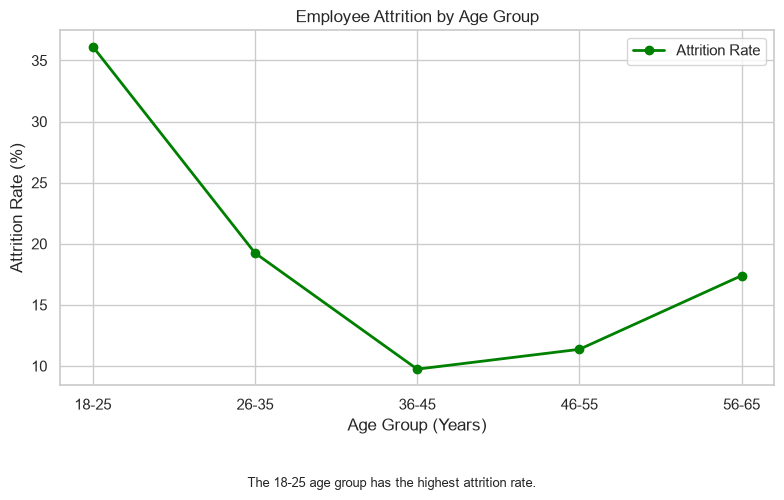

Insight: The 18-25 age group has the highest attrition rate.


In [5]:
# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

# Calculate attrition percentage
age_attrition = (
    df.groupby("AgeGroup", observed=False)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

plt.figure(figsize=(8, 5))

plt.plot(
    age_attrition.index.astype(str),
    age_attrition.values,
    marker="o",
    color="green",
    linewidth=2,
    label="Attrition Rate"
)

plt.title("Employee Attrition by Age Group")
plt.xlabel("Age Group (Years)")
plt.ylabel("Attrition Rate (%)")
plt.legend()

insight = (
    f"The {age_attrition.idxmax()} age group has "
    f"the highest attrition rate."
)

plt.figtext(0.5, 0.01, insight, ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    r"C:\Users\Admin\Desktop\Training\Python Training\25-11-2026\Task_3\reports\figures\04_age_attrition_line.png"
)

plt.show()

print("Insight:", insight)

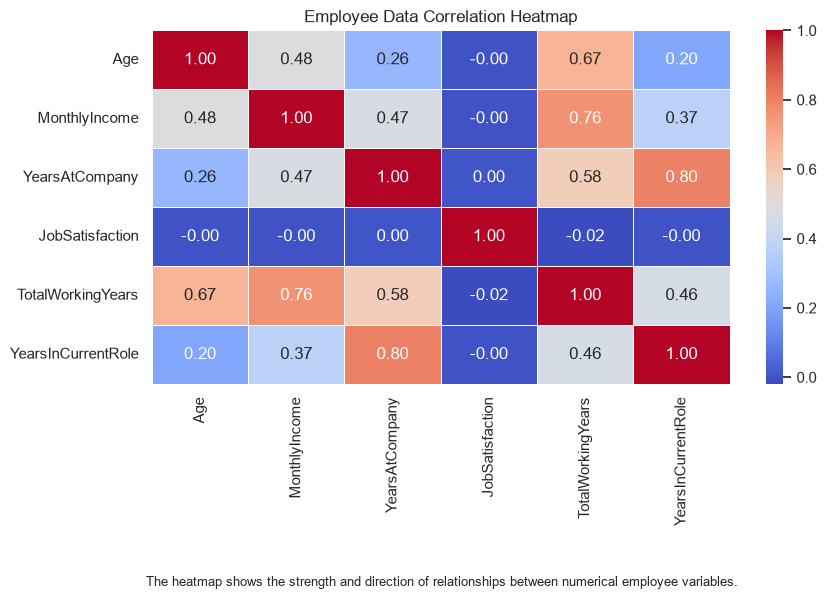

Insight: The heatmap shows the strength and direction of relationships between numerical employee variables.


In [6]:
# Select numerical columns
numeric_data = df[
    [
        "Age",
        "MonthlyIncome",
        "YearsAtCompany",
        "JobSatisfaction",
        "TotalWorkingYears",
        "YearsInCurrentRole"
    ]
]

# Calculate correlation
correlation = numeric_data.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Employee Data Correlation Heatmap")

insight = (
    "The heatmap shows the strength and direction "
    "of relationships between numerical employee variables."
)

plt.figtext(0.5, 0.01, insight, ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    r"C:\Users\Admin\Desktop\Training\Python Training\25-11-2026\Task_3\reports\figures\05_employee_correlation_heatmap.png"
)

plt.show()

print("Insight:", insight)